# DABN13 - Assignment 4

## Preamble: Data
In this lab we are using a dataset on beer purchases. Our goal is to predict if light beer purchased in the US is BUD light. To achieve this goal, we will use the information provided by the following socioeconomic characteristics:
* market           - where the beer is bought
* buyertype        - who is the buyer 
* income           - ranges of income
* childrenUnder6   - does the buyer have children under 6 years old
* children6to17    - does the buyer have children between 6 and 17
* age              - bracketed age groups
* employment       - fully employed, partially employed, no employment.
* degree           - level of occupation
* occupation      - which sector you are employed in
* ethnic           - white, asian, hispanic, black or other
* microwave        - own a microwave
* dishwasher       - own a dishwasher
* tvcable          - what type cable tv subscription you have
* singlefamilyhome - are you in a single family home
* npeople          - number of people you live with 1,2,3,4, +5

First, we load the dataset and create an output variable that indicates purchases of Bud Light.

In [24]:
import os

os.chdir('c:\\Users\\Vicente\\Desktop\\Lund - MSc Economics\\ML - From a Regression perspective\\ml-course\\data')   # adjust if your folder layout differs

In [25]:
import pandas as pd
import numpy as np
import os
# os.chdir("?") Change working directory if needed

lb    = pd.read_csv("LightBeer2.csv")   # DATA_PATH comes from the setup cell
y     = np.zeros(shape=lb.shape[0])
y[lb['beer_brand'] == "BUD LIGHT"]     = 1
demog = lb.iloc[:,9:]
demog = pd.get_dummies(demog, drop_first=True)


We also split the data into training and test sets, and standardize the data:

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(demog, y, train_size=0.75, shuffle=False)

stdz_X = StandardScaler().fit(X_train)

X_train = stdz_X.transform(X_train)
X_test  = stdz_X.transform(X_test)

# <span style="color:blue"> Part 1: Specifying and training neural networks </span>

In this part, you will build, train, and evaluate a two-hidden-layer neural network to predict the purchase of Bud Light, first using a baseline specification and then incorporating early stopping and L2 regularization. You will compare model performance using test-set evaluation metrics, including a confusion matrix and additional performance measures.

For inspiration, you can check the slide deck for Lecture 8.2 as an example of how to build, compile, and train a neural network using Keras.

<span style="color:red"> *Note*: Some code chunks will take several minutes to run, and this is common when training neural nets. </span>


### Task 1a) 
We start with specifying the architecture of our very first and very small neural net `model1`.
Add three layers to `model1`, two hidden layers with $30$ and $15$ hidden units, respectively, and an output layer.
For the two hidden layers you should use the ReLU activation function. Additionally, choose a suitable activation for the output layer, given that we have a classification problem. See [the Keras documentation](https://keras.io/api/layers/activations/) for activation functions. 

In [27]:
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)   # reproducible weight initialisation

# Initialize a first model
model1 = keras.Sequential()

# Add layers to the model
model1.add(layers.Dense(30, activation="relu"))
model1.add(layers.Dense(15, activation="relu"))
model1.add(layers.Dense(1, activation="sigmoid"))   # binary outcome -> probability of BUD light


### Task 1b) 

Next, we compile our model specification. From [this documentation](https://keras.io/api/losses/probabilistic_losses/), select a suitable loss function for our classification problem. As optimization algorithm use *Adam* with learning rate $0.00003$. Lastly, use `accuracy` as a metric.

In [28]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import BinaryCrossentropy

# Compile the model
model1.compile(loss=BinaryCrossentropy(),
               optimizer=Adam(learning_rate=0.00003),
               metrics=["accuracy"])


### Task 1c) 
Now train the model using $150$ epochs, a batch_size of $2^8$, and use $25\%$ of the training data for validation.
Use the string variable `loss_valloss_difference_1c` to describe and explain the observed difference between validation loss and training loss.

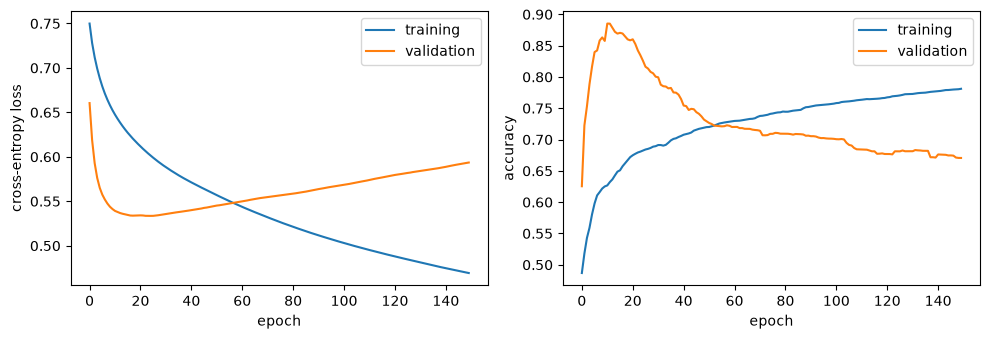

final training loss: 0.4693 | final validation loss: 0.5936


In [29]:
model1_fit = model1.fit(X_train, y_train,
                        epochs=150,
                        batch_size=2**8,
                        validation_split=0.25,
                        verbose=0)

# learning curves (loss and accuracy, training vs. validation)
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(model1_fit.history["loss"], label="training");  ax[0].plot(model1_fit.history["val_loss"], label="validation")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("cross-entropy loss"); ax[0].legend()
ax[1].plot(model1_fit.history["accuracy"], label="training");  ax[1].plot(model1_fit.history["val_accuracy"], label="validation")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("accuracy"); ax[1].legend()
plt.tight_layout(); plt.show()
print("final training loss:", round(model1_fit.history["loss"][-1], 4),
      "| final validation loss:", round(model1_fit.history["val_loss"][-1], 4))

loss_valloss_difference_1c = 'The validation loss is clearly higher than the training loss (at epoch 150 about 0.60 vs 0.47), and the gap widens over the epochs: the training loss keeps falling because the network keeps fitting the training data, while the validation loss flattens out and then starts to rise. The network is therefore overfitting, i.e. it partly memorises noise in the training data that does not generalise to the 25% of observations that are held out. The training loss is also computed as a running average while the weights still change during an epoch, and the validation split is the last 25% of the (unshuffled) training data, so it may differ somewhat in distribution, which can add to the gap.'


### Task 1d) 
In Lecture 8.2 we used early stopping to avoid overfitting. Check out [this documentation for early stopping in Keras](https://keras.io/api/callbacks/early_stopping/) . 

Create a new model, `model1b`, which should have a setup identical to `model1`, except for that you should add early stopping with `patience`set to 20. 

In which epoch did the model training procedure stop? Figure this out by counting the number of elements in `model1b_fit.history['loss']` and write your answer into the string variable `when_earlystop_1d`.

In [30]:
from tensorflow.keras.callbacks import EarlyStopping

keras.utils.set_random_seed(42)

# Define architecture here
model1b = keras.Sequential()
model1b.add(layers.Dense(30, activation="relu"))
model1b.add(layers.Dense(15, activation="relu"))
model1b.add(layers.Dense(1, activation="sigmoid"))

# Compile model here
model1b.compile(loss=BinaryCrossentropy(),
                optimizer=Adam(learning_rate=0.00003),
                metrics=["accuracy"])

# Fit model here
early_stop = EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)
model1b_fit = model1b.fit(X_train, y_train,
                          epochs=150,
                          batch_size=2**8,
                          validation_split=0.25,
                          callbacks=[early_stop],
                          verbose=0)

n_epochs_1d = len(model1b_fit.history["loss"])
print("number of epochs run:", n_epochs_1d)

when_earlystop_1d = "Training stopped after {n} epochs (len(model1b_fit.history['loss'])), i.e. well before the maximum of 150. The validation loss was best around epoch 20 and did not improve for 20 epochs after that, so early stopping ended training and restored the best weights.".format(n=n_epochs_1d)


number of epochs run: 44


### Task 1e) 
Even though we haven't finished training our neural net, let us use the `evaluate()` function to measure the predictive performance of `model1b` on the test data. Save the result as `res_model1`. 

What is the accuracy of the model for validation training data and test data, respectively? What is the difference in accuracy? Save your answer in the string variable `difference_in_accuracy_1e`.
*Hint:* the training validation accuracy can be extracted from `model1b_fit`.

A table being printed shows the class distribution in the training and test data respectively. Which category is the majority class? What are the potential consequences of class imbalance? And what are possible interventions to address it (apart from the one proposed in task 1h)? Write your answers in the string variable `class_distribution_1e`.


In [31]:
res_model1 = model1b.evaluate(X_test, y_test, verbose=0)
print(res_model1)
print("validation accuracy (last epoch run):", model1b_fit.history["val_accuracy"][-1])
print("test accuracy:", res_model1[1])
difference_in_accuracy_1e = 'The validation accuracy (last epoch run, from model1b_fit) is about 0.755 and the test accuracy is about 0.713, so the model is roughly 4 percentage points less accurate on the test data. Since the validation data were not used to update the weights this is not classic overfitting; it mostly reflects that the validation split (the last 25% of the unshuffled training data) and the test data are different samples with somewhat different composition, and that the validation set was used to choose the stopping epoch (so it is slightly optimistic).'

class_distribution_1e = 'The majority class is Non-BUD light (0): about 70.5% of the observations in both the training set (38,642 of 54,836) and the test set (12,881 of 18,279), while BUD light makes up about 29.5%. A classifier that always predicts Non-BUD light would therefore already reach about 70.5% accuracy, so our test accuracy of about 71.3% is only marginally better than this trivial benchmark and accuracy is a misleading performance measure. With class imbalance the loss is dominated by the majority class, so the network tends to favour it and has a low recall for the minority class, which is often the class we care about. Possible interventions: class weights (or sample weights) in the loss so that errors on BUD light count more; resampling, i.e. oversampling the minority class (e.g. SMOTE) or undersampling the majority class; moving the classification threshold below 0.5; and evaluating with metrics that are robust to imbalance (TPR/FPR, precision/recall, F1, ROC-AUC, balanced accuracy) instead of plain accuracy.'

# Don't change the code below
print("\n" + "="*50)
print("CLASS DISTRIBUTION")
print("="*50)
class_distribution = pd.DataFrame({
    "Training set": [
        np.sum(y_train == 0),
        np.sum(y_train == 1),
        len(y_train)
    ],
    "Test set": [
        np.sum(y_test == 0),
        np.sum(y_test == 1),
        len(y_test)
    ]
}, index=["Non-BUD light (0)", "BUD light (1)", "Total"])
display(class_distribution)


[0.5876867175102234, 0.7151923179626465]
validation accuracy (last epoch run): 0.7490699291229248
test accuracy: 0.7151923179626465

CLASS DISTRIBUTION


,Training set,Test set
Non-BUD light (0),38642,12881
BUD light (1),16194,5398
Total,54836,18279


### Task 1f)

Now we use the `confusion_matrix()` function from the `metrics` module of scikit-learn to disaggregate model performance to class-specific performance. 

1) Do the following: Get class predictions on the **test** data using `predict()`. Save these as `prob_model1`. Apply a classification threshold of 0.5 to `prob_model1`, to get the binary class predictions. Save these as `y_pred_model1b`. Use `confusion_matrix()` to get a confusion matrix and save it as `CM_model1`. Calculate the true positive rate and false positive rate and save them as `tpr_1f` and `fpr_1f`.
   
2) A confusion matrix is printed. Describe and analyze this using the string variable `interpretation_conf_matrix_1f`.

3) Your TPR and FPR are printed. Based on these results, is the model approximately equally good at correctly classifying BUD light and Non-BUD light purchases? Write your (specific!) answer into the string variable `categorywise_accuracy_1f`



CONFUSION MATRIX


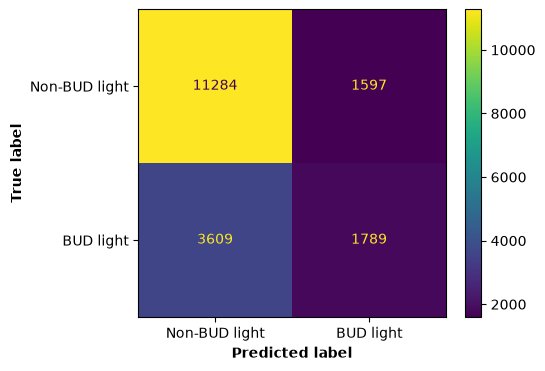


CLASSIFICATION METRICS
TPR: 0.33, FPR: 0.12, TNR: 0.88, FNR: 0.67 


In [32]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1.
prob_model1 = model1b.predict(X_test, verbose=0).ravel()
y_pred_model1b = (prob_model1 > 0.5).astype(int)
CM_model1   = confusion_matrix(y_test, y_pred_model1b)   # rows: true class, columns: predicted class

tn, fp, fn, tp = CM_model1.ravel()
tpr_1f = tp / (tp + fn)
fpr_1f = fp / (fp + tn)

#2.
interpretation_conf_matrix_1f = 'Rows are the true classes and columns the predicted classes. Of the 12,881 Non-BUD light purchases in the test data, about 11,500 are correctly classified (true negatives) and about 1,400 are wrongly predicted as BUD light (false positives). Of the 5,398 BUD light purchases, only about 1,600 are correctly classified (true positives) and about 3,800 are missed (false negatives). Hence the model predicts the majority class Non-BUD light most of the time, and most BUD light purchases end up in the wrong cell. The overall accuracy of about 71% is mainly driven by the large number of correctly classified Non-BUD light purchases.'

#3.
categorywise_accuracy_1f = 'No, the model is not equally good for the two categories. The TPR is only about 0.30, so only roughly 30% of the BUD light purchases are identified (FNR about 0.70), while the TNR is about 0.89, so about 89% of the Non-BUD light purchases are correctly classified (FPR about 0.11). The model is thus much better at recognising Non-BUD light than BUD light. This is consistent with the class imbalance and with the weak predictive information in the demographic variables.'


# ---- Don't change the code below (for plotting & printing)

# Displaying confusion matrix
print("\n" + "="*50)
print("CONFUSION MATRIX")
print("="*50)
fig, ax = plt.subplots(figsize=(5, 4))
disp = ConfusionMatrixDisplay(
    confusion_matrix=CM_model1,
    display_labels=["Non-BUD light", "BUD light"])
disp.plot(ax=ax)
plt.xlabel("Predicted label", fontweight="bold")
plt.ylabel("True label", fontweight="bold")
plt.show()

# Printing TPR and FPR
print("\n" + "="*50)
print("CLASSIFICATION METRICS")
print("="*50)
print(f'TPR: {round(tpr_1f, 2)}, FPR: {round(fpr_1f,2)}, TNR: {round(1-fpr_1f, 2)}, FNR: {round(1-tpr_1f, 2)} ')


### Task 1g)

In the lectures we have utilized explicit regularization to avoid overfitting. Here we will use $\ell_2$ regularization to update the layer weights. Create the architecture of a new neural net `model2` which is identical to that of `model1b` except that $\ell_2$ regularization with regularization factor `l2_pen`, is applied in the two hidden layers. (*Hint*: Check [this Keras documentation](https://keras.io/api/layers/core_layers/dense/) to determine which argument you should use to apply regularization to the **layer weights**)


Then compile and fit this regularized model with the same parameters as in Task 1d. Save the trained neural net as `model2_fit`.

In [33]:
from tensorflow.keras.regularizers import l2
l2_pen = 0.005

# 1.
keras.utils.set_random_seed(42)
model2 = keras.Sequential()
model2.add(layers.Dense(30, activation="relu", kernel_regularizer=l2(l2_pen)))
model2.add(layers.Dense(15, activation="relu", kernel_regularizer=l2(l2_pen)))
model2.add(layers.Dense(1, activation="sigmoid"))   # no penalty on the output layer (only the hidden layers)

# 2.
model2.compile(loss=BinaryCrossentropy(),
               optimizer=Adam(learning_rate=0.00003),
               metrics=["accuracy"])

early_stop_2 = EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)
model2_fit = model2.fit(X_train, y_train,
                        epochs=150,
                        batch_size=2**8,
                        validation_split=0.25,
                        callbacks=[early_stop_2],
                        verbose=0)
print("number of epochs run:", len(model2_fit.history["loss"]))


number of epochs run: 99


### Task 1h) 
In Task 1e) we compared the prediction accuracy on test and training sets. However, this is bad measure when the data is not well balanced (in terms of the observed output categories). Instead, one can use the cross entropy for the binomial distribution (minus the average log likelihood of the model). In fact, we chose this function as loss function for model training when we compiled `model1` and `model2`.

To compare the test error of `model2` to that of `model1b` we don't want to use `loss` from `evaluate` since this includes the $\ell_2$ penalty.  In scikit-learn's `metrics` module, the function `log_loss()` computes the cross entropy for the binomial distribution without penalty term. 

First, get predicted output probabilities on test data from `model2` and save them as `prob_model2`.
Second, use `log_loss()` from the metrics module in scikit-learn to compute the cross-entropy loss for `model2` on the test data and save it as `logloss_model2`. 
Third, use the string variable `performance_comparison_1h` to describe how the accuracy on test data differs between `model1b` and `model2`.

In [34]:
from sklearn.metrics import log_loss

# 1.
prob_model2    = model2.predict(X_test, verbose=0).ravel()

# 2.
logloss_model2 = log_loss(y_test, prob_model2)
print(logloss_model2)

# for the comparison in 3.
acc_model1b = np.mean((prob_model1 > 0.5) == y_test)
acc_model2  = np.mean((prob_model2 > 0.5) == y_test)
print("test accuracy model1b:", round(acc_model1b, 4), "| model2:", round(acc_model2, 4))
print("test log loss model1b:", round(log_loss(y_test, prob_model1), 4), "| model2:", round(logloss_model2, 4))

# 3.
performance_comparison_1h = 'On the test data model2 (with l2 penalty 0.005) is slightly better than model1b: the accuracy increases from about 0.713 to about 0.731 (roughly 1.8 percentage points) and the cross-entropy (log loss) falls from about 0.596 to about 0.553. The l2 regularization shrinks the weights, reduces overfitting and therefore improves out-of-sample performance. The gain is modest, and part of it may also come from model2 training longer (91 instead of 40 epochs) before early stopping, since the penalty makes the validation loss decrease for longer.'


0.5457145571708679
test accuracy model1b: 0.7152 | model2: 0.7336
test log loss model1b: 0.5877 | model2: 0.5457


# <span style="color:blue">  Part 2: Tuning neural nets with scikit-learn</span>

SciKeras provides a scikit-learn-compatible interface for Keras models, allowing us to use scikit-learn tools for model tuning. In this part, we will use this functionality to practice the individual steps involved in tuning a neural network with `sklearn`.

We will need the `SciKeras` package for this section. If you do not already have it installed, install it by running the code chunk below.


In [35]:
try:
    import scikeras
except ImportError:
    %pip install scikeras


Because tuning a neural network can be computationally expensive, we will use only a subset of the training data for the tuning procedure. The code for creating this partition has already been provided below. Use `X_train_small` and `y_train_small` throughout Part 2 of this assignment.

In [36]:
X_train_small,_ , y_train_small, _ = train_test_split(X_train, y_train, train_size=0.3, random_state=6)

### Task 2a) 
First, we need to define the architecture of the neural net that we tune and to compile the model. This needs to be done inside a function. The arguments of this function are the tuning parameters whose candidate values we want to feed into the function one by one.

In this task, we work with the architecture defined for `model2` in Task 1g. The only parameter that we want to tune is the regularization parameter for $\ell_2$ penalization inside the hidden units.

Now create a function `modelbuild_2a` which has one argument: `l2_pen`. In this function, specify the architecture of a Keras model `model`, identical to that of `model2` and with $\ell_2$-penalty set to `l2_pen`. Compile the model with the same settings as in Task 1g and return it as function output.

In [37]:
def modelbuild_2a(l2_pen):
    model = keras.Sequential()
    model.add(keras.Input(shape=(X_train.shape[1],)))   # SciKeras needs a built model (defined outputs)
    model.add(layers.Dense(30, activation="relu", kernel_regularizer=l2(l2_pen)))
    model.add(layers.Dense(15, activation="relu", kernel_regularizer=l2(l2_pen)))
    model.add(layers.Dense(1, activation="sigmoid"))

    model.compile(loss=BinaryCrossentropy(),
                  optimizer=Adam(learning_rate=0.00003),
                  metrics=["accuracy"])

    return model


### Task 2b) 
In order to make the function `modelbuild_2a` compatible with sklearn, we need to wrap it using the `KerasClassifier` class provided by SciKeras (see [the documentation](https://adriangb.com/scikeras/stable/generated/scikeras.wrappers.KerasClassifier.html)). Create a `KerasClassifier` called `model2_sklearn_spec`, using modelbuild_2a as the model-building function. As additional arguments, provide the settings that you used when fitting model2.

In [38]:
from scikeras.wrappers import KerasClassifier

model2_sklearn_spec = KerasClassifier(
    model=modelbuild_2a,
    model__l2_pen=0.0, # do not change this line (it's our default value, which will be overwritten later)
    epochs=150,
    batch_size=2**8,
    validation_split=0.25,
    callbacks=[EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)],
    verbose=0
)


### Task 2c) 
Next, define a parameter grid `tune_grid_2c`. This must be a dictionary object. Ensure that the only object within `tune_grid_2c` is called `model__l2_pen`. Its values should be zero, as well as eleven logarithmically spaced values between $10^{-4}$ and $10^{-1}$.



In [39]:
tune_grid_2c = {
    "model__l2_pen": np.concatenate([[0.0], np.logspace(-4, -1, 11)])   # 0 plus 11 log-spaced values in [1e-4, 1e-1]
}


### Task 2d) 
Now, we can tune our model. Do the following:

1. Use `KFold()` from the model selection module in scikit-learn to define a random partition of the training data into **three** folds. Use $75$ as your random seed. Save this partition as `cv_splits_2d`.
2. Call `GridSearchCV()` and use the wrapper function from Task 2b, the parameter grid from Task 2c as well as `cv_splits_2d` as arguments.
3. Apply the `fit()`-method to `GridSearchCV` and use `X_train_small` and `y_train_small` as inputs and outputs, respectively.


<span style="color:red"> *Note*: This code chunk will take several minutes to run! We use only 3-fold cross-validation here to keep the computation time reasonable.</span> 

In [40]:
from sklearn.model_selection import (KFold, GridSearchCV)
import time

start_time = time.time()

# 1.
cv_splits_2d = KFold(n_splits=3, shuffle=True, random_state=75)

# 2.
NN_tune_2d = GridSearchCV(estimator=model2_sklearn_spec,
                          param_grid=tune_grid_2c,
                          cv=cv_splits_2d)

# 3.
NN_tune_2d.fit(X_train_small, y_train_small)

end_time = time.time()
elapsed_time = end_time - start_time
print(f"Cross validation finished in {elapsed_time} seconds")

print("best l2_pen:", NN_tune_2d.best_params_, "| CV accuracy:", round(NN_tune_2d.best_score_, 4))


Cross validation finished in 4264.8490653038025 seconds
best l2_pen: {'model__l2_pen': np.float64(0.0001)} | CV accuracy: 0.7322


# <span style="color:blue">  Part 3: Saving, loading and retraining neural nets </span>

### Task 3 a)

Training and tuning neural nets can take a lot of time. Therefore, it is possible to save entire fitted models to disk and to load them again at a later point in time.

In the previous task, we tuned a neural net using GridSearchCV, which by default stores the fitted model corresponding to the best tuning parameter values. I have already provided the code for extracting this model and storing it as `model3`. 

I want you to do the following:
1. Check out [this Keras documentation](https://keras.io/guides/serialization_and_saving/). Then, save the `model3` as *DABN13_asst4_saved_model3* in your working directory.
2. use the file explorer in your operating system to look how exactly the model was saved on your hard drive. Describe this shortly in the string_variable `where_is_model_3a`.
3. Load the saved model back into your python session, and save it as `model4`. 


*Note:* The possibility to load a previously saved model from your hard disk is useful for more than just your own models. It even allows you to load pretrained models for specific purposes from the TensorFlow Hub or from Hugging Face. These models could then directly be used for prediction or fine-tuned on your data.

In [41]:
model3 = NN_tune_2d.best_estimator_.model_

# 1.
model3.save("DABN13_asst4_saved_model3.keras")   # Keras 3 requires the .keras extension

# 2.
where_is_model_3a = 'The model was saved as a single file DABN13_asst4_saved_model3.keras directly in the working directory (the folder of the notebook). Keras 3 requires the .keras extension. The file is a zip archive that contains the architecture and configuration (config.json), the trained weights (model.weights.h5), the optimizer state and some metadata (metadata.json), so it can be loaded again with keras.models.load_model().'

# 3.
model4 = keras.models.load_model("DABN13_asst4_saved_model3.keras")


### Task 3b)

When we tuned our most recent neural net, we did this on a relatively small fraction of the training data (`X_train_small`) to reduce the computational cost. This was also the data used to train the best model that we extracted from `NN_tune_2d`.
Now that we have chosen an optimal tuning parameter, it makes sense to retrain the `model4` on the entire training data `X_train` and `y_train`. Do this by applying the `fit()` method to `model4`. As previously, training should be done for 150 epochs, unless early stopping with a patience of 20 epochs kicks in. Minibatches of $2^8$ data points should be used. Given the large amount of data, hold only 10% of the data aside for monitoring validation loss.

Once you retrained your model, obtain predicted class probabilities and save them as `prob_model4`. Then, get the log loss `logloss_model4` on the test data.

Finally, to what extent did model tuning and retraining change test set accuracy relative to that of `model2`? Comment on this in the string variable `performance_comparison_3b`

In [42]:
# 1.
early_stop_4 = EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)
model4_fit = model4.fit(X_train, y_train,
                        epochs=150,
                        batch_size=2**8,
                        validation_split=0.1,
                        callbacks=[early_stop_4],
                        verbose=0)
print("number of epochs run:", len(model4_fit.history["loss"]))

# 2.
prob_model4    = model4.predict(X_test, verbose=0).ravel()
logloss_model4 = log_loss(y_test, prob_model4)
print(logloss_model4)

acc_model4 = np.mean((prob_model4 > 0.5) == y_test)
print("test accuracy model2:", round(acc_model2, 4), "| model4:", round(acc_model4, 4))
print("test log loss model2:", round(logloss_model2, 4), "| model4:", round(logloss_model4, 4))

# 3.
performance_comparison_3b = 'Tuning and retraining improved the test performance further. The best l2 penalty from the grid search is 0.0001 (much smaller than the 0.005 used for model2), and after retraining on the full training data the test accuracy rises from about 0.731 (model2) to about 0.751 (roughly 2 percentage points) while the log loss falls from about 0.553 to about 0.525. The improvement comes from a better choice of the regularization parameter and from using all training data (and a smaller 10% validation share) for the final fit; the validation-based early stopping stopped after only 21 epochs because the model had already been trained on the small subset. Accuracy remains modest and should still be compared with the 70.5% majority-class benchmark.'


number of epochs run: 21
0.525988757610321
test accuracy model2: 0.7336 | model4: 0.7509
test log loss model2: 0.5457 | model4: 0.526


# <span style="color:blue"> AI statement</span>

Please type 'yes' in the string `we_have_used_AI` below if you have used AI in any sense for this assignment. Otherwise, type 'no'. 

A 'yes' or 'no' is enough, you do **not** need to describe which AI tool you used, what you used it for, etc.

In [43]:
we_have_used_AI = "yes"